# Import thư viện

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Đọc dữ liệu đầu vào

In [5]:
df = pd.read_csv('../../Dataset/data_raw/winequality-red.csv', sep=';')
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


# Xem thông tin dữ liệu ban đầu

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


# Xem mô tả dữ liệu

In [7]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


# Kiểm tra giá trị thiếu và dòng trùng trong dữ liệu

In [8]:
print("Null theo cột:")
print(df.isnull().sum())
print("Số lượng hàng trùng lặp:")
print(df.duplicated().sum())

Null theo cột:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Số lượng hàng trùng lặp:
240


# Xem phân phối chất lượng rượu

In [9]:
print(df["quality"].value_counts().sort_index())

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


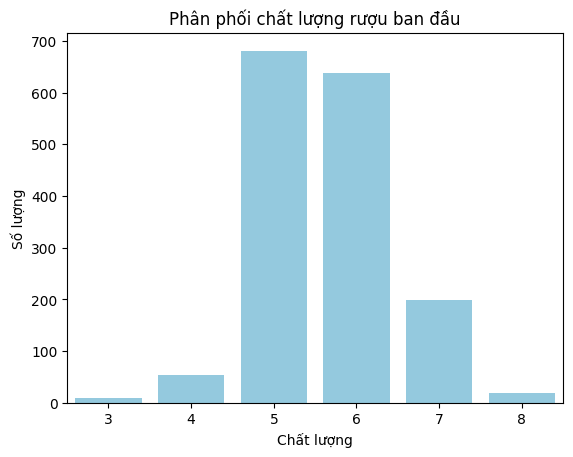

In [10]:
sns.countplot(x='quality', data=df, color='skyblue')
plt.title('Phân phối chất lượng rượu ban đầu')
plt.xlabel('Chất lượng')
plt.ylabel('Số lượng')
plt.show()

# Xem Outlier của các biến 

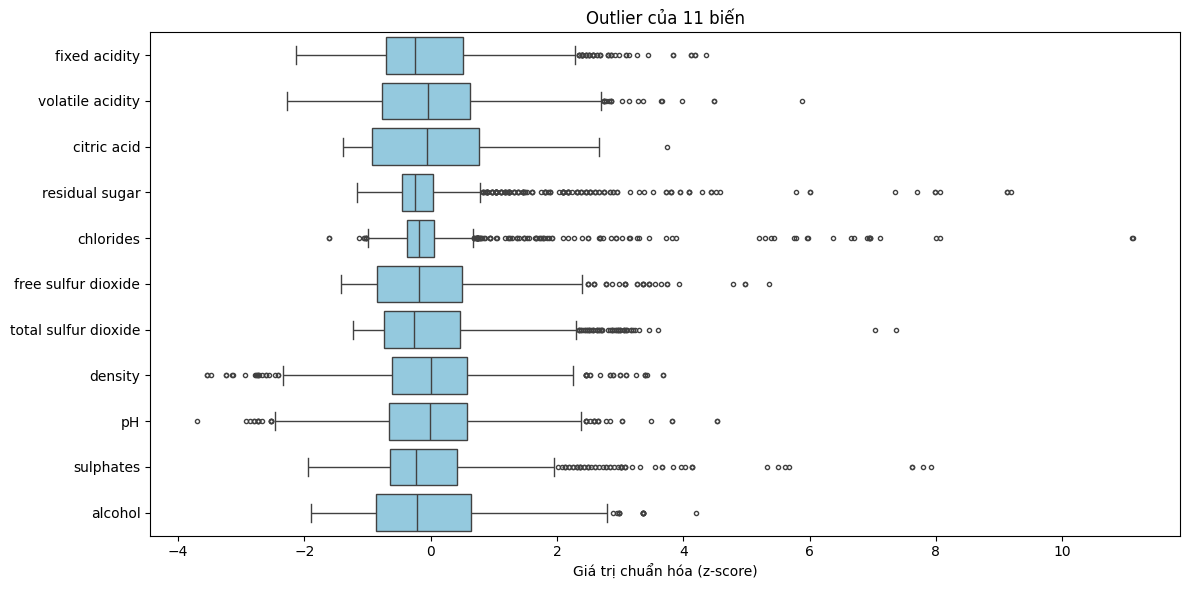

In [11]:
features = df.drop(columns="quality").columns
z = (df[features] - df[features].mean()) / df[features].std()

plt.figure(figsize=(12, 6))
sns.boxplot(data=z, orient="h", color="skyblue", fliersize=3)
plt.xlabel("Giá trị chuẩn hóa (z-score)")
plt.title("Outlier của 11 biến")
plt.tight_layout()
plt.show()

## Kiểm tra Domain

In [12]:
print("free SO2 > total SO2:", int((df["free sulfur dioxide"] > df["total sulfur dioxide"]).sum()))
print("Giá trị âm:", int((df[features] < 0).sum().sum()))
print("pH trong [0, 14]:", bool(df["pH"].between(0, 14).all()))

free SO2 > total SO2: 0
Giá trị âm: 0
pH trong [0, 14]: True


# Ma trận tương quan

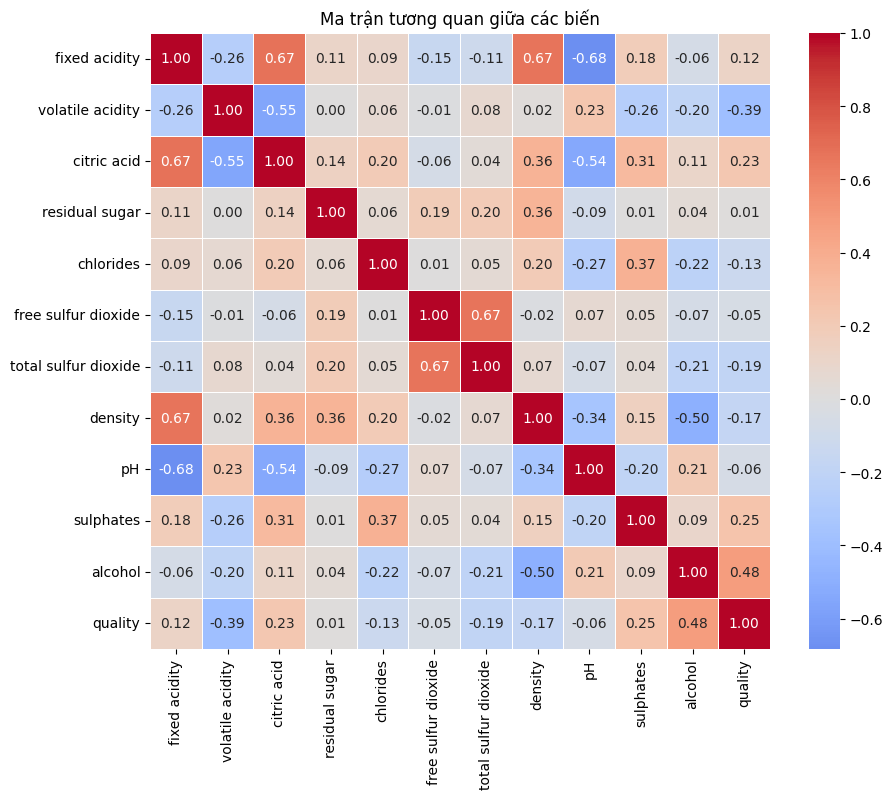

In [13]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0, linewidths=0.5)
plt.title("Ma trận tương quan giữa các biến")
plt.show()

# Làm sạch
Ở đây, nhóm sẽ thực hiện bỏ các dòng trùng để làm sạch dữ liệu, giữ outlier.

## Loại bỏ dòng trùng

In [14]:
df_cleaned = df.copy()
df_cleaned = df_cleaned.drop_duplicates()
df_cleaned

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
5,7.4,0.660,0.00,1.8,0.075,13.0,40.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1593,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


Kiểm tra lại một lần nữa:

In [15]:
print("Số dòng trùng còn lại: ", int(df_cleaned.duplicated().sum()))

Số dòng trùng còn lại:  0


In [16]:
print("Phân phối chất lượng rượu sau khi làm sạch:")
print(df_cleaned["quality"].value_counts().sort_index())

Phân phối chất lượng rượu sau khi làm sạch:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


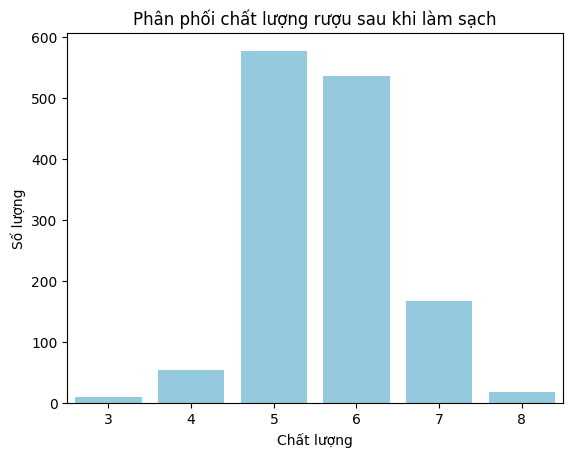

In [17]:
sns.countplot(x='quality', data=df_cleaned, color='skyblue')
plt.title('Phân phối chất lượng rượu sau khi làm sạch')
plt.xlabel('Chất lượng')
plt.ylabel('Số lượng')
plt.show()

## Chia biến target thành 3 lớp

Nhóm sẽ phân chia các mức độ chất lượng thành 3 lớp cụ thể dưới đây:
- Lớp 0: quality ≤ 4 -> Chất lượng thấp 
- Lớp 1: quality từ 5 đến 6 -> Chất lượng trung bình 
- Lớp 2: quality ≥ 7 -> Chất lượng cao

Phân phối 3 lớp:
  0 (low): 63
  1 (medium): 1112
  2 (high): 184


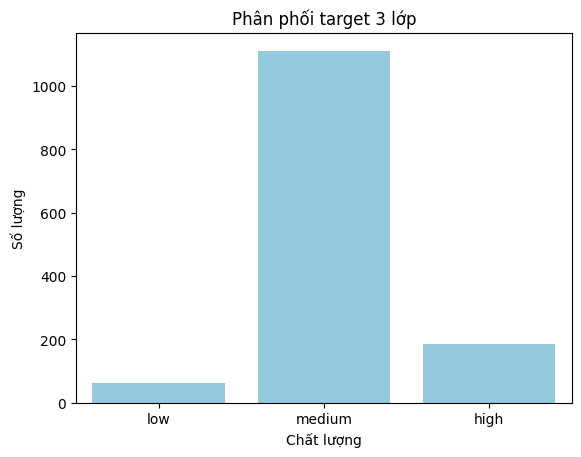

In [18]:
def map_quality(q):
    if q <= 4:
        return 0  
    if q <= 6:
        return 1  
    return 2  

LABEL_NAME = {0: "low", 1: "medium", 2: "high"}

df_cleaned["quality_raw"] = df_cleaned["quality"]
df_cleaned["quality"] = df_cleaned["quality_raw"].apply(map_quality)

print("Phân phối 3 lớp:")
counts = df_cleaned["quality"].value_counts().sort_index()
for k in counts.index.tolist():
    print(f"  {k} ({LABEL_NAME[int(k)]}): {counts[k]}")

sns.countplot(x="quality", data=df_cleaned, color="skyblue")
plt.xticks([0, 1, 2], ["low", "medium", "high"])
plt.title("Phân phối target 3 lớp")
plt.xlabel("Chất lượng")
plt.ylabel("Số lượng")
plt.show()

## Lưu vào file dữ liệu đã làm sạch

In [19]:
df_cleaned.to_csv("../../Dataset/data_cleaned/winequality-red_clean.csv", index=False)
print("Dữ liệu đã được làm sạch và lưu vào file winequality-red_clean.csv'")

Dữ liệu đã được làm sạch và lưu vào file winequality-red_clean.csv'


# Chia dữ liệu

In [20]:
df_cleaned = pd.read_csv("../../Dataset/data_cleaned/winequality-red_clean.csv")
df_cleaned

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_raw
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,1,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,1,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,1,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,1,6
4,7.4,0.660,0.00,1.8,0.075,13.0,40.0,0.99780,3.51,0.56,9.4,1,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1354,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,1,6
1355,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,1,5
1356,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,1,6
1357,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,1,5


In [21]:
LABEL_NAME = {0: "low", 1: "medium", 2: "high"}

X = df_cleaned.drop(columns=["quality", "quality_raw"])
y = df_cleaned["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Kích thước tập huấn luyện:", X_train.shape)
print("Kích thước tập kiểm tra:", X_test.shape)

Kích thước tập huấn luyện: (1087, 11)
Kích thước tập kiểm tra: (272, 11)


## Lưu lại thành các tập dữ liệu

In [22]:
pd.concat([X_train, y_train], axis=1).to_csv("../../Dataset/data_split/train_data.csv", index=False )
pd.concat([X_test, y_test], axis=1).to_csv("../../Dataset/data_split/test_data.csv", index=False )
print("Dữ liệu huấn luyện và kiểm tra đã được lưu vào các file 'train_data.csv' và 'test_data.csv'")

Dữ liệu huấn luyện và kiểm tra đã được lưu vào các file 'train_data.csv' và 'test_data.csv'
